# Can you trust your AI rater?
### A follow-along evaluation walkthrough · Shamiri Summit 2026 · Tech track

**Session:** Developing AI Evaluation Systems You Can Trust

Shamiri trains university-age **Fellows** to deliver group sessions in secondary schools. Supervisors check each session's **fidelity**: did the Fellow deliver the protocol, and deliver it well? Humans can't listen to every session, so we built an AI pipeline to help:

```
session recording ──► transcription (ASR) ──► LLM judge ──► 6 rubric scores (1–7)
                                                          ├─► written feedback
                                                          └─► safety flags ──► supervisor
```

This notebook walks through **how we evaluated that pipeline**, one step at a time. Each step ends with a lesson you can take back to your own AI system.

> **All data here is synthetic.** It is generated in the first cell and contains no real students, Fellows, schools or recordings. It was tuned so the *patterns* resemble what we found on real data. The numbers will not match ours exactly, and the lessons hold either way.

**How to follow along:** in Google Colab, choose *Runtime → Run all*, then scroll. Or run one cell at a time with **Shift + Enter**. Cells marked **Your turn** invite you to change something and re-run it.

## Setup
Run this cell first. It builds the synthetic dataset: 180 group sessions, two human ratings each, an AI judge run three times on identical input, a second prompt version, a transcription sample, and a seeded safety test set. You don't need to read it. In Colab it shows as a collapsed form.

In [1]:
# @title Setup: build the synthetic dataset (run me, no need to read) { display-mode: "form" }
import numpy as np, pandas as pd, matplotlib.pyplot as plt, re, warnings
from scipy import stats
from sklearn.metrics import cohen_kappa_score, roc_auc_score
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3); pd.set_option("display.width", 120); pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

DIMS = ["protocol_adherence", "content_specifications", "thoroughness",
        "skillful_delivery", "clarity_accessibility", "protocol_boundaries"]

def _build(seed=2026, N=180):
    rng = np.random.default_rng(seed)
    t = rng.normal(0, 1, N)                       # hidden "true" session quality
    ids = [f"S{i:03d}" for i in range(1, N + 1)]
    sessions = pd.DataFrame({
        "session_id": ids,
        "school": rng.choice([f"School {c}" for c in "ABCDEFGH"], N),
        "session_type": rng.choice(["s1", "s2", "s3", "s4"], N),
        "fellow_id": [f"F{x:02d}" for x in rng.integers(1, 31, N)],
        "audio_sha": [f"{x:012x}" for x in rng.integers(0, 2**48, N)],
    })
    # --- human raters: lenient, noisy, crowded at the top of the scale, uneven workload
    raters = [f"R{i}" for i in range(1, 9)]
    workload = np.array([.40, .18, .12, .10, .08, .06, .04, .02])
    lean = dict(zip(raters, rng.normal(0, .35, 8)))
    rows = []
    for i in range(N):
        for slot, r in enumerate(rng.choice(raters, 2, replace=False, p=workload), start=1):
            y = np.clip(np.rint(5.95 + .55 * t[i] + lean[r] + rng.normal(0, .8) + rng.normal(0, .9, 6)), 1, 7)
            rows.append({"session_id": ids[i], "rater_slot": slot, "rater_id": r, **dict(zip(DIMS, y))})
    human = pd.DataFrame(rows)
    # --- AI judge, prompt v1: harsh, one collapsed item, re-draw noise; 3 draws on identical input
    mu_v1 = np.array([2.45, 4.8, 3.25, 3.2, 5.9, 6.25])
    load = np.array([.01, 1, 1, 1, 1, 1]) * .7
    opinion = rng.normal(0, .5, (N, 6)) + rng.normal(0, .4, (N, 1))   # the judge's stable view of each session
    ai = []
    def draws(mu, load, version, n_draws, noise=.45):
        for d in range(1, n_draws + 1):
            run_noise = rng.normal(0, noise, (N, 6)) + rng.normal(0, .3, (N, 1))
            sc = np.clip(np.rint(mu + np.outer(t, load) + opinion + run_noise), 1, 7)
            for i in range(N):
                ai.append({"session_id": ids[i], "prompt_version": version, "draw": d, **dict(zip(DIMS, sc[i]))})
    draws(mu_v1, load, "v1", 3)
    # --- prompt v2: the over-strict adherence clause rewritten; everything else unchanged
    mu_v2 = mu_v1.copy(); mu_v2[0] = 4.9
    load_v2 = load.copy(); load_v2[0] = .7
    draws(mu_v2, load_v2, "v2", 1)
    ai = pd.DataFrame(ai)
    for c in DIMS: ai[c] = ai[c].astype(int)

    # --- plant the data-hygiene problems we actually met
    raw = human.copy()
    for c in DIMS: raw[c] = raw[c].astype("Int64")
    raw["overall_score"] = raw[DIMS].sum(axis=1).astype("Int64")
    bad_total = rng.choice(len(raw), 6, replace=False)
    raw.loc[bad_total, "overall_score"] = raw.loc[bad_total, "overall_score"] - rng.choice([-10, 10, 7], 6)
    missing = rng.choice(len(raw), 3, replace=False)
    for k, m in enumerate(missing): raw.loc[m, DIMS[k * 2]] = pd.NA
    dup_src = rng.choice(N, 4, replace=False)      # the same recording filed under a second id
    dups, extra_sessions = [], []
    for k, s in enumerate(dup_src):
        new_id = f"S{N + 1 + k:03d}"
        extra = sessions.iloc[s].copy(); extra["session_id"] = new_id; extra_sessions.append(extra)
        d = raw[raw.session_id == ids[s]].copy(); d["session_id"] = new_id; dups.append(d)
    raw = pd.concat([raw] + dups, ignore_index=True)
    sessions_raw = pd.concat([sessions, pd.DataFrame(extra_sessions)], ignore_index=True)
    return sessions_raw, raw, ai

sessions_raw, human_raw, ai_scores = _build()

# --- five synthetic clips: scripted, spoken by text-to-speech, transcribed by a real model (see Step 3)
REPO_RAW = "https://raw.githubusercontent.com/Shamiri-Institute/fidelity-eval-demo/main/"   # public raw-file URL of the repo; empty means use the copy embedded below
try:
    asr_clips = pd.read_csv(REPO_RAW + "data/asr_demo.csv")
except Exception:
    import io; asr_clips = pd.read_csv(io.StringIO(r"""clip_id,verbatim,human_a,human_b,ai_model,ai_model_run2
clip_01,okay guys karibuni tena eh today we are talking about gratitude who can tell me what gratitude means it is like um being thankful for what you have sawa sawa exactly being thankful even for small things kwa mfano mimi niko grateful for my mum manze nice one and how did that make you feel nilifeel poa sana like nimeheshimiwa na mimi niko grateful juu jana tulikula chapo nyumbani aah chapo hiyo ni kitu ya kushukuru kabisa eh teacher hata small things kama tea ya asubuhi inacount inacount sana that is the whole point we notice the small things so let us write three things we are grateful for this week tunaandika kwa notebook ama kwa paper kwa notebook ni sawa then tutashare na the group,"Okay guys, karibuni tena. Today we are talking about gratitude. Who can tell me what gratitude means? It is like being thankful for what you have. Sawa, exactly, being thankful even for small things. Kwa mfano mimi niko grateful for my mum. Nice one. How did that make you feel? Nilifeel poa sana, like nimeheshimiwa. Na mimi niko grateful juu jana tulikula chapo nyumbani. Chapo hiyo ni kitu ya kushukuru kabisa. Teacher, hata small things kama tea ya asubuhi inacount? Inacount sana. That is the whole point, we notice the small things. So let us write three things we are grateful for. Tunaandika kwa notebook ama paper? Kwa notebook ni sawa, then tutashare na group.","Ok guys karibuni tena, today we're talking about gratitude Who can tell me what gratitude means It's like being thankful for what you have Sawasawa, exactly, being thankful for small things Kwa mfano mimi niko grateful for my mum, maze Nice one, how did that make you feel I felt very good, like I was respected Na mimi niko grateful coz jana tulikula chapati home Chapo hio ni kitu ya kushukuru kabisa Eh teacher, hata vitu ndogo kama chai ya asubuhi inacount Inacount sana, that's the whole point, we notice the small things So let's write 3 things we're grateful for this week Tunaandika kwa notebook ama paper Notebook ni sawa then tutashare na group","Okay guys, karibuni tena eh? Today, we are talking about gratitude. Who can tell me what gratitude means? It is like, um, being thankful for what you have. Sawasawa, exactly, being thankful even for small things. Kwa mfano, mimi niko grateful for my mum manze. Nice one, and how did that make you feel? Nice one, and how did that make you feel? Nilifeel poa sana, like nimeheshimiwa. Na mimi niko grateful juu jana tulikula chapo nyumbani. Ah chapo, hiyo ni kitu ya kushukuru kabisa. Eh teacher, hata small things kama tea ya asubuhi inaccount? Inacount sana, that is the whole point. We notice the small things. So, let us write three things we are grateful for this week. Tunaandika kwa notebook ama kwa paper? Kwa notebook ni sawa then tutashare na the group.","Okay guys, karibuni tena eh? Today, we are talking about gratitude. Who can tell me what gratitude means? It is like um being thankful for what you have. Sawasawa. Exactly. Being thankful even for small things. Kwa mfano, mimi niko grateful for my mom, manze. Nice one. And how did that make you feel? Nice one. And how did that make you feel? Nilifeel poa sana, like nimeheshimiwa. Na mimi niko grateful ju jana tulikula chapo nyumbani. Ah, chapo, hiyo ni kitu ya kushukuru kabisa. Eh, teacher, hata small things kama tea asubuhi inaccount. Inaccount sana. That is the whole point. We notice the small things. So let us write three things we are grateful for this week. Tunaandika kwa notebook ama kwa paper? Kwa notebook ni sawa. Then tutashare na the group."
clip_02,sasa leo tunaongea about growth mindset mmh who remembers from last week ni ile story ya brain kama muscle yes exactly the brain grows when you practise ukitry vitu ngumu but teacher mimi maths hainiingii hata nikitry aje okay so instead of saying siwezi maths we can say siwezi maths bado bado eh like not yet yes not yet that one word inabadilisha kila kitu kwa mfano last term nilikuwa nafail chemistry but nikaanza kusoma na friend wangu and how did it go nilipata B minus um so imeimprove wueh hiyo ni growth mindset kabisa kila mtu apige makofi so mistakes ni sawa mistakes ni sawa they show us where to practise more,,,"Sasa, leo tunaongea about growth mindset. Mm, who remembers from last week? Ni ile story ya brain kama muscle? Yes, exactly. The brain grows when you practice ukitry vitu ngumu. But teacher, mi maths haiingii, hata nikitry aje. Okay, so instead of saying ""Siwezi maths"", we can say, ""Siwezi maths bado"". ""Bado"", eh? Like ""not yet""? Yes, ""not yet"". That one word inabadilisha kila kitu. Kwa mfano, last term nilikuwa nafail chemistry, but nikaanza kusoma na friend wangu. And how did it go? Nilipata B minus. Um, so imeimprove. Weh, hiyo ni growth mindset kabisa. Kila mtu ampigie makofi. So, mistakes ni sawa? Mistakes ni sawa. They show us where to practice more.","Sasa, leo tunaongea about growth mindset. Mmh who remembers from last week? Ni ile stori ya brain kama muscle? Yes, exactly! The brain grows when you practice ukitry vitu ngumu. But teacher, mimi maths haiingii, hata nikitry aje. Okay, so instead of saying, ""Siwezi maths,"" we can say, ""Siwezi maths bado."" Bado, eh? Like, not yet? Yes, not yet! That one word inabadilisha kila kitu. Kwa mfano, last term nilikuwa nafail chemistry, but nikaanza kusoma na friend wangu. And how did it go? Nilipata B minus, um so imeimprove. Weeh! Hiyo ni growth mindset kabisa! Kila mtu ampigie makofi. So, mistakes ni sawa? Mistakes ni sawa, they show us where to practice more."
clip_03,before tuanze let us do a quick check in kila mtu aseme siku yake imekuwa aje on a scale of one to ten mimi niko seven juu tumetoka games na tukashinda aah congratulations mlicheza nini football tulibeat form three mimi niko like eight eh nimeamka poa leo niko six juu niko na njaa kidogo haha sawa lunch iko karibu mimi niko nine teacher ju kesho ni weekend weekend vibes eh okay asanteni wote for sharing na mimi niko eight because I am happy kuwa hapa na nyinyi so today tutaongea about strengths and how we use them every day,,,"Before tuanze, let us do a quick check-in. Kila mtu aseme siku yake imekuwa aje on a scale of 1 to 10. Mimi niko seven juu tumetoka games na tukashinda. Ah, congratulations! Mlicheza nini? Football, tulibeat form three. Mi niko like eight, eh? Nimeamka poa leo. Niko six juu niko na njaa kidogo. Haha, sawa. Lunch iko karibu. Mimi niko nine, teacher, juu kesho ni weekend. Weekend vibes, eh? Okay, asanteni wote for sharing. Na mimi niko eight because I am happy kuwa hapa na nyinyi. So today tutaongea about strengths and how we use them everyday.","Before tuanze, let us do a quick check-in. Kila mtu aseme siku yake imekuwa aje on a scale of 1 to 10. Mimi niko seven juu tumetoka games na tukashinda. Ah, congratulations! Mlicheza nini? Football. Tulibeat form three. Mi niko like eight, eh? Nimeamka poa leo. Niko six, juu niko na njaa kidogo. Sawa. Lunch iko karibu. Mimi niko nine, teacher, juu kesho ni weekend. Weekend vibes, eh? Okay, asanteni wote for sharing. Na mimi niko eight because I am happy kuwa hapa na nyinyi. So, today tutaongea about strengths and how we use them everyday."
clip_04,okay guys leo tunaongea about values ni nini kitu inakuguide kwa maisha um kama honesty honesty yes give me an example kama ukipata pesa kwa field unarudisha kwa mwenyewe sawa sawa hiyo ni honesty kabisa who else mimi naona respect ni value kubwa sana especially kwa wazazi na kusaidia wengine like ukiona mtu amebeba vitu mingi unamsaidia that one tunaita kindness or compassion teacher kuna difference between values na rules good question rules ni zile umeambiwa na mtu mwingine but values ni zile wewe mwenyewe umechagua aah sasa nimeelewa so kila mtu achague value moja ya kufocus on this week,,,"Okay guys, leo tunaongea about values. Ni nini kitu inaku-guide kwa maisha? Erm kama honesty. Honesty, yes. Give me an example. Kama ukipata pesa kwa field, unarudisha kwa mwenyewe. Sawasawa, hiyo ni honesty kabisa. Who else? Mimi naona respect ni value kubwa sana, especially kwa wazazi. Na kusaidia wengine, like ukiona mtu amebeba vitu mingi unamsaidia. That one tunaita kindness or compassion. Teacher, kuna difference between values na rules? Good question. Rules ni zile umeambiwa na mtu mwingine, but values ni zile wewe mwenyewe umechagua. Ah, sasa nimeelewa. So, kila mtu achague value moja ya kufocus on this week.","Okay guys, leo tunaongea about values. Ni nini kitu inaku-guide kwa maisha? Um, kama honesty? Honesty, yes. Give me an example. Kama, ukipata pesa kwa field, unarudisha kwa mwenyewe. Sawa sawa. Hiyo ni honesty kabisa. Who else? Mimi naona respect ni value kubwa sana, especially kwa wazazi. Na kusaidia wengine, like, ukiona mtu amebeba vitu mingi, unamsaidia. That one tunaita kindness or compassion. Teacher, kuna difference between values na rules? Good question. Rules ni zile umeambiwa na mtu mwingine, but values ni zile wewe mwenyewe umechagua. Ah, sasa nimeelewa. So, kila mtu achague value moja ya kufocus on this week."
clip_05,last week tuliweka goals so let us see how far mmefika goal yangu ilikuwa kuamka mapema na nimejaribu ehe na imeenda aje monday na tuesday niliamka saa kumi na moja but wednesday nililala haha it happens two out of three si mbaya mimi nilisema nitasoma pages tano kila siku na nimefanya hivyo nimemaliza kitabu moja wow a whole book congratulations ilikuwa ya nini ni story ya msichana anaenda shule mbali mbali mine ilikuwa kudrink maji more um sijafanya vizuri lakini nimeanza kuanza ndio step ya kwanza so for this week ni goal gani mtaweka nitabeba bottle ya maji kila siku poa sana that is a small step that is easy to check,,,"Last week tuliweka goals, so let us see how far mmefika. Goal yangu ilikuwa kuamka mapema, na nimejaribu. Ehee na imeendaje? Monday na Tuesday niliamka 5:00 but Wednesday nililala. Haha, it happens 2 out of 3 si mbaya. Mimi nilisema nitasoma pages 5 kila siku, na nimefanya hivyo nimemaliza kitabu moja. Wow, a whole book? Congratulations! Ilikuwa ya nini? Ah ni story ya msichana anaenda shule mbalimbali. Mine ilikuwa kudrink maji more. Um, sijafanya vizuri lakini nimeanza. Kuanza ndiyo step ya kwanza. So for this week, ni goal gani mtaweka? Nitabeba botol ya maji kila siku. Poa sana. That is a small step that is easy to check.","Last week tuliweka goals, so let us see how far mmefika. Goal yangu ilikuwa kuamka mapema na nimejaribu. Ehe! Na imeenda aje? Monday na Tuesday niliamka 11:00 am, but Wednesday nililala. Haha, it happens. Two out of three si mbaya. Mimi nilisema nitasoma pages tano kila siku. Na nimefanya hivyo, nimemaliza kitabu moja. Wow, a whole book? Congratulations! Ilikuwa ya nini? Ah, ni story ya msichana anaenda shule mbalimbali. Mine ilikuwa kudrink maji more. Um, sijafanya vizuri lakini nimeanza. Kuanza ndiyo step ya kwanza. So for this week, ni goal gani mtaweka? Nitabeba botol ya maji kila siku. Poa sana. That is a small step that is easy to check."
"""))
asr_clips = asr_clips.fillna("")

# --- seeded safety test set: 20 genuine current-risk cases, 40 look-alikes (no real disclosures; labels only)
_r = np.random.default_rng(7)
_kinds = (["current distress, stated plainly"] * 8 + ["current distress, indirect wording"] * 6 +
          ["current distress, in Sheng"] * 4 + ["current distress, split across turns"] * 2)
_look = (["story about a past, resolved event"] * 16 + ["hypothetical in a role-play"] * 12 +
         ["teaching example from the manual"] * 12)
safety = pd.DataFrame({"case_id": [f"C{i:02d}" for i in range(1, 61)],
                       "scenario": _kinds + _look,
                       "is_current_risk": [True] * 20 + [False] * 40})
safety["ai_flagged"] = True
safety.loc[[19], "ai_flagged"] = False                       # misses one split-across-turns case
safety.loc[_r.choice(range(20, 60), 13, replace=False), "ai_flagged"] = False
safety["ai_timeframe"] = np.where(safety.is_current_risk, "current",
    safety.scenario.map({"story about a past, resolved event": "past",
                         "hypothetical in a role-play": "hypothetical",
                         "teaching example from the manual": "educational"}))
safety.loc[[24, 41], "ai_timeframe"] = "current"            # two look-alikes the model mislabels
safety.loc[~safety.ai_flagged, "ai_timeframe"] = None

print("Built:")
print(f"  human_raw     {human_raw.shape[0]} rating rows over {human_raw.session_id.nunique()} session ids")
print(f"  ai_scores     {ai_scores.shape[0]} rows (prompt v1 x 3 draws, prompt v2 x 1 draw)")
print(f"  asr_clips     {len(asr_clips)} synthetic recordings, each transcribed twice by a real model")
print(f"  safety        {len(safety)} seeded test cases")

Built:
  human_raw     368 rating rows over 184 session ids
  ai_scores     720 rows (prompt v1 x 3 draws, prompt v2 x 1 draw)
  asr_clips     5 synthetic recordings, each transcribed twice by a real model
  safety        60 seeded test cases


---
## Step 1 · Audit the reference before you trust it

Every number in an evaluation is measured *against* something: here, two human supervisors' ratings of each session. That reference is a measuring instrument, and it needs quality control like any other.

Four checks that caught real problems for us:
1. **Duplicates.** Is the same recording filed under two ids? Then your "held-out" set may hold sessions you already tuned on.
2. **Missing scores.**
3. **Totals that don't add up.** Is the stored `overall_score` really the sum of the items?
4. **Who did the rating.** If one person rated most sessions, your "human standard" is that one person's habits.

In [2]:
print("Rows:", len(human_raw), "| session ids:", human_raw.session_id.nunique())
human_raw.head()

Rows: 368 | session ids: 184


,session_id,rater_slot,rater_id,protocol_adherence,content_specifications,thoroughness,skillful_delivery,clarity_accessibility,protocol_boundaries,overall_score
0,S001,1,R2,6,5,4,5,5,5,30
1,S001,2,R6,7,7,6,7,6,7,40
2,S002,1,R3,7,7,7,7,7,7,42
3,S002,2,R2,4,6,5,4,5,5,29
4,S003,1,R2,5,4,4,5,4,5,27


In [3]:
# 1. Same audio under different session ids
ids_per_audio = sessions_raw.groupby("audio_sha").session_id.agg(list)
dup_groups = ids_per_audio[ids_per_audio.str.len() > 1]
print(f"1. Duplicate recordings: {len(dup_groups)} groups")
for ids in dup_groups: print("     ", " = ".join(ids))

# 2. Missing item scores
missing = human_raw[human_raw[DIMS].isna().any(axis=1)]
print(f"\n2. Rows with a missing item score: {len(missing)}")

# 3. Stored total vs recomputed total
recomputed = human_raw[DIMS].sum(axis=1, min_count=6)
bad_total = human_raw[(recomputed.notna()) & (recomputed != human_raw.overall_score)]
print(f"\n3. Rows where overall_score != sum of items: {len(bad_total)}")

# 4. Workload per rater
print("\n4. Share of ratings by rater:")
print((human_raw.rater_id.value_counts(normalize=True) * 100).round(0).astype(int).astype(str).add("%").to_string())

1. Duplicate recordings: 4 groups
      S057 = S182
      S114 = S183
      S075 = S184
      S065 = S181

2. Rows with a missing item score: 3

3. Rows where overall_score != sum of items: 6

4. Share of ratings by rater:
rater_id
R1    31%
R2    20%
R4    14%
R3    12%
R5    10%
R6     7%
R8     4%
R7     3%


In [4]:
# Clean: keep one id per recording, drop sessions without two complete ratings, recompute totals
drop_ids = [ids[1:] for ids in dup_groups]
drop_ids = [i for group in drop_ids for i in group]
human = human_raw[~human_raw.session_id.isin(drop_ids)].copy()
complete = human.groupby("session_id")[DIMS].apply(lambda g: g.notna().all().all() and len(g) == 2)
human = human[human.session_id.isin(complete[complete].index)].copy()
human[DIMS] = human[DIMS].astype(int)
human["composite"] = human[DIMS].mean(axis=1)
print(f"Clean reference: {human.session_id.nunique()} sessions, each rated by two people")

Clean reference: 177 sessions, each rated by two people


**Lesson 1.** Your golden dataset is a measuring instrument. Audit it, fix it, and freeze it (hash the files) *before* you score anything against it.

**Your turn:** look at check 4. If rater R1 did 40% of the ratings and is unusually lenient, what happens to an AI that is "calibrated to the humans"?

---
## Step 2 · Measure the humans first

Before asking "does the AI agree with humans?", ask **"do humans agree with each other?"** Two trained supervisors rated every session independently, so we can measure that directly.

- **Exact / within ±1:** how often the two scores match, or are at most one point apart
- **QWK** (quadratic weighted kappa): agreement corrected for chance
- **ICC:** how much of the variation in scores is real differences between sessions, rather than rater noise (1 = perfect, 0 = pure noise)

In [5]:
def icc_a1(x):
    """ICC(A,1): two-way, absolute agreement, single rater. x: sessions x raters."""
    x = np.asarray(x, float); n, k = x.shape; gm = x.mean()
    msr = k * ((x.mean(axis=1) - gm) ** 2).sum() / (n - 1)
    msc = n * ((x.mean(axis=0) - gm) ** 2).sum() / (k - 1)
    mse = ((x - x.mean(axis=1, keepdims=True) - x.mean(axis=0, keepdims=True) + gm) ** 2).sum() / ((n - 1) * (k - 1))
    return (msr - mse) / (msr + (k - 1) * mse + k * (msc - mse) / n)

wide = human.pivot(index="session_id", columns="rater_slot")
rows = []
for d in DIMS + ["composite"]:
    a, b = wide[(d, 1)].values, wide[(d, 2)].values
    rows.append({"dimension": d,
                 "exact %": np.mean(np.rint(a) == np.rint(b)) * 100 if d != "composite" else np.nan,
                 "within ±1 %": np.mean(np.abs(a - b) <= 1) * 100 if d != "composite" else np.nan,
                 "QWK": cohen_kappa_score(a.astype(int), b.astype(int), weights="quadratic") if d != "composite" else np.nan,
                 "ICC": icc_a1(np.c_[a, b])})
human_agreement = pd.DataFrame(rows).set_index("dimension")
human_agreement.round(2)

,exact %,within ±1 %,QWK,ICC
dimension,,,,
protocol_adherence,31.64,63.84,0.10,0.10
content_specifications,25.99,67.23,0.15,0.15
thoroughness,30.51,68.36,0.11,0.11
skillful_delivery,29.94,61.02,0.13,0.13
clarity_accessibility,24.86,66.10,0.12,0.12
protocol_boundaries,28.25,69.49,0.17,0.17
composite,NaN,NaN,NaN,0.23


In [6]:
icc = human_agreement.loc["composite", "ICC"]
share_high = (human[DIMS].values >= 6).mean()
print(f"{share_high:.0%} of all item scores are a 6 or a 7: most of the scale goes unused.")
print(f"Composite ICC between two trained raters: {icc:.2f}")

# What does that permit? Spearman-Brown: reliability of the average of k raters
sb = lambda r, k: k * r / (1 + (k - 1) * r)
print("\nReliability if we averaged k raters:")
for k in [1, 2, 3, 5, 10]: print(f"   k={k:>2}: {sb(icc, k):.2f}")

ceiling_1 = np.sqrt(icc)            # best possible correlation of ANY judge with one rater
ceiling_2 = np.sqrt(sb(icc, 2))     # ... with the average of two raters
print(f"\nCeiling vs one rater:        r ≤ {ceiling_1:.2f}")
print(f"Ceiling vs two-rater average: r ≤ {ceiling_2:.2f}")

62% of all item scores are a 6 or a 7: most of the scale goes unused.
Composite ICC between two trained raters: 0.23

Reliability if we averaged k raters:
   k= 1: 0.23
   k= 2: 0.37
   k= 3: 0.47
   k= 5: 0.60
   k=10: 0.75

Ceiling vs one rater:        r ≤ 0.48
Ceiling vs two-rater average: r ≤ 0.61


Even a *perfect* AI could not correlate with these humans above the ceiling, because the humans don't agree with each other. So an AI scoring r = 0.45 here is not "mediocre". It may be close to the best possible.

**Lesson 2.** Measure human agreement first, and report every AI-vs-human number **next to that ceiling, never against 1.0**. If the ceiling is low, the cheapest improvement may be rater training and anchored rubric examples, not a better model.

---
## Step 3 · Check the upstream component: the transcript

The judge reads a transcript, not audio. If the transcript is wrong, the scores measure the transcription, not the Fellow.

Real evaluations have a gap here: nobody knows exactly what was said, so you score the model against a human transcript and hope the human got it right. For this demo we closed that gap:

| | what it is |
|---|---|
| **script** | Five short sessions we wrote in code-switched English, Swahili and Sheng. Synthetic. |
| **audio** | Each script read aloud by text-to-speech, one voice per speaker. Synthetic. Takes where the voice repeated or ad-libbed a line were re-recorded, so the script is exactly what was said. |
| **model** | Real output from `gemini-3.7-flash`, the transcription model from our evaluation, run **twice** on each clip. |
| **human A, human B** | Clip 1 only. **Hand-written** to show two common transcriber styles. Not real transcribers. |

In [7]:
import textwrap
from IPython.display import Audio
clip1 = asr_clips.set_index("clip_id").loc["clip_01"]
if REPO_RAW: display(Audio(REPO_RAW + "audio/clip_01.mp3"))
for col, label in [("verbatim", "SCRIPT (what was said)"), ("human_a", "HUMAN A"),
                   ("human_b", "HUMAN B"), ("ai_model", "MODEL")]:
    print(f"── {label}\n{textwrap.fill(clip1[col], 100)}\n")

── SCRIPT (what was said)
okay guys karibuni tena eh today we are talking about gratitude who can tell me what gratitude means
it is like um being thankful for what you have sawa sawa exactly being thankful even for small
things kwa mfano mimi niko grateful for my mum manze nice one and how did that make you feel
nilifeel poa sana like nimeheshimiwa na mimi niko grateful juu jana tulikula chapo nyumbani aah
chapo hiyo ni kitu ya kushukuru kabisa eh teacher hata small things kama tea ya asubuhi inacount
inacount sana that is the whole point we notice the small things so let us write three things we are
grateful for this week tunaandika kwa notebook ama kwa paper kwa notebook ni sawa then tutashare na
the group

── HUMAN A
Okay guys, karibuni tena. Today we are talking about gratitude. Who can tell me what gratitude
means? It is like being thankful for what you have. Sawa, exactly, being thankful even for small
things. Kwa mfano mimi niko grateful for my mum. Nice one. How did that make 

In [8]:
# Normalise before comparing: case, punctuation, contractions, numbers, and a few
# spelling conventions (hio/hiyo, ndo/ndio). A compact copy of our evaluation's rules.
CONTRACTIONS = {"it's": "it is", "that's": "that is", "we're": "we are", "let's": "let us",
                "i'm": "i am", "you're": "you are", "don't": "do not", "can't": "can not"}
FOLD = {**{w: "h" + w for w in "ii iyo izi izo uyu uyo awa ao apa apo uku uko ivi ivyo ata adi".split()},
        "hio": "hiyo", "ndo": "ndio", "ndiyo": "ndio", "practise": "practice", "maths": "math"}
NUMS = ("zero one two three four five six seven eight nine ten eleven twelve thirteen "
        "fourteen fifteen sixteen seventeen eighteen nineteen twenty").split()

def norm(s):
    s = re.sub(r"[^\w'\-\s]", " ", s.lower().replace("’", "'"))
    s = re.sub(r"(?<!\w)['\-]|['\-](?!\w)", " ", s)
    words = [FOLD.get(w, w) for t in s.split() for w in CONTRACTIONS.get(t, t).split()]
    return [n for w in words for n in
            ([NUMS[int(w)]] if w.isdigit() and int(w) <= 20 else [NUMS[int(d)] for d in w] if w.isdigit() else [w])]

def edit_distance(a, b):
    prev = list(range(len(b) + 1))
    for i, x in enumerate(a, 1):
        cur = [i]
        for j, y in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (x != y)))
        prev = cur
    return prev[-1]

def wer(ref, hyp):
    r, h = norm(ref), norm(hyp); return edit_distance(r, h) / len(r)
def cer(ref, hyp):
    r, h = " ".join(norm(ref)), " ".join(norm(hyp)); return edit_distance(r, h) / len(r)

NAMES = {"verbatim": "script", "human_a": "human A", "human_b": "human B",
         "ai_model": "model", "ai_model_run2": "model, 2nd run"}
pairs = [("verbatim", "human_a"), ("verbatim", "human_b"), ("verbatim", "ai_model"),
         ("human_a", "human_b"), ("human_a", "ai_model"), ("human_b", "ai_model"),
         ("ai_model", "ai_model_run2")]
asr = pd.DataFrame([{"reference": NAMES[r], "compared with": NAMES[h],
                     "CER": cer(clip1[r], clip1[h]), "WER": wer(clip1[r], clip1[h])} for r, h in pairs])
asr.round(3)

,reference,compared with,CER,WER
0,script,human A,0.066,0.087
1,script,human B,0.123,0.198
2,script,model,0.062,0.103
3,human A,human B,0.132,0.183
4,human A,model,0.132,0.183
5,human B,model,0.179,0.258
6,model,"model, 2nd run",0.008,0.030


Read the table from the top:
- **Against the truth, the model does about as well as the careful human** (CER 0.06 each), and better than human B, who translated a line into English.
- **The two humans disagree with each other more than the model errs.** If human B were your only reference, the model would look about three times worse than it is. Much of what gets called "model error" is the **reference**.
- **The model barely disagrees with itself.** Two runs on the same audio differ by about 1% of characters. Two people transcribing the same audio don't come close to that.

This is the same pattern we found on real sessions: two transcribers of the same recording agreed less with each other than either agreed with the model.

In [9]:
per_clip = pd.DataFrame({"CER: model vs script": [cer(c.verbatim, c.ai_model) for c in asr_clips.itertuples()],
                         "CER: model vs its 2nd run": [cer(c.ai_model, c.ai_model_run2) for c in asr_clips.itertuples()]},
                        index=asr_clips.clip_id)
print(per_clip.round(3).to_string(), "\n")
print("mean:", per_clip.mean().round(3).to_dict())

         CER: model vs script  CER: model vs its 2nd run
clip_id                                                 
clip_01                 0.062                      0.008
clip_02                 0.013                      0.008
clip_03                 0.011                      0.010
clip_04                 0.008                      0.005
clip_05                 0.043                      0.023 

mean: {'CER: model vs script': 0.028, 'CER: model vs its 2nd run': 0.011}


In [10]:
import difflib
print("Every place the model's clip-1 transcript differs from the script:")
r, h = norm(clip1.verbatim), norm(clip1.ai_model)
for op, i1, i2, j1, j2 in difflib.SequenceMatcher(None, r, h, autojunk=False).get_opcodes():
    if op != "equal":
        print(f"   said: {' '.join(r[i1:i2]) or '(nothing)':12s} → model wrote: {' '.join(h[j1:j2]) or '(nothing)'}")

Every place the model's clip-1 transcript differs from the script:
   said: sawa sawa    → model wrote: sawasawa
   said: (nothing)    → model wrote: nice one and how did that make you feel
   said: aah          → model wrote: ah
   said: inacount     → model wrote: inaccount


In [11]:
print("Why CER (characters) and not just WER (words) for code-switched speech:")
for ref, hyp in [("sawa sawa", "sawasawa"), ("manze", "maze"), ("nilifeel poa", "nilifil poa")]:
    print(f"   '{ref}' vs '{hyp}':  WER {wer(ref, hyp):.2f}   CER {cer(ref, hyp):.2f}")

Why CER (characters) and not just WER (words) for code-switched speech:
   'sawa sawa' vs 'sawasawa':  WER 1.00   CER 0.11
   'manze' vs 'maze':  WER 1.00   CER 0.20
   'nilifeel poa' vs 'nilifil poa':  WER 0.50   CER 0.17


Notice three things:
- **The Sheng and Swahili came through almost untouched.** The model's differences are spelling conventions (`sawa sawa` / `sawasawa`, `aah` / `ah`) plus **one real error: it wrote a whole sentence twice.** Repeating a span is a known failure of this kind of model, and it matters downstream: a judge counting how often the Fellow asked about feelings would count that question twice.
- **WER punishes a one-letter spelling difference in Sheng as a whole wrong word.** CER is fairer to languages without a fixed spelling, so lead with CER.
- **Be honest about what this test can't show.** This audio is clean: one speaker at a time, no overlap, no classroom noise. It is easier than a real session, so treat these error rates as a floor, not an estimate.

The question that matters is the downstream one: *does a worse transcript change the fidelity score?* Test it directly: score the same sessions from a human transcript and from the model transcript, and compare the scores pairwise.

**Lesson 3.** Evaluate each stage on its own, and check how good the reference is before blaming the model. Then ask whether the stage's errors change the final output at all.

---
## Step 4 · Score the judge against the humans

Now the main event: the LLM judge's six scores (prompt v1, first run) against the average of the two human raters.

In [12]:
v1 = ai_scores[ai_scores.prompt_version == "v1"]
ai1 = v1[v1.draw == 1].set_index("session_id")
hmean = human.groupby("session_id")[DIMS + ["composite"]].mean()
ai1 = ai1.loc[hmean.index]
ai1["composite"] = ai1[DIMS].mean(axis=1)

judge = pd.DataFrame([{"dimension": d, "AI mean": ai1[d].mean(), "human mean": hmean[d].mean(),
                       "bias (AI−human)": ai1[d].mean() - hmean[d].mean(),
                       "r": stats.pearsonr(ai1[d], hmean[d])[0]} for d in DIMS + ["composite"]]).set_index("dimension")
judge.round(2)

,AI mean,human mean,bias (AI−human),r
dimension,,,,
protocol_adherence,2.42,5.84,-3.42,-0.04
content_specifications,4.88,5.76,-0.88,0.41
thoroughness,3.33,5.81,-2.49,0.38
skillful_delivery,3.32,5.73,-2.40,0.40
clarity_accessibility,5.93,5.73,0.19,0.30
protocol_boundaries,6.20,5.69,0.51,0.36
composite,4.35,5.76,-1.41,0.51


Composite r = 0.51 against a ceiling of 0.61  ->  83% of what is achievable
The ranking is real. The calibration is not: the AI sits 1.4 points below the humans on a 1–7 scale.



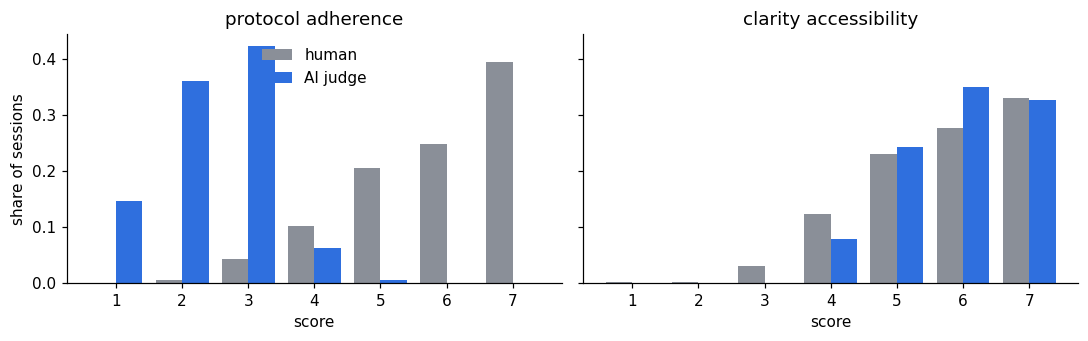

In [13]:
r_comp = judge.loc["composite", "r"]
print(f"Composite r = {r_comp:.2f} against a ceiling of {ceiling_2:.2f}  ->  {r_comp / ceiling_2:.0%} of what is achievable")
print("The ranking is real. The calibration is not: the AI sits "
      f"{-judge.loc['composite', 'bias (AI−human)']:.1f} points below the humans on a 1–7 scale.\n")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, d in zip(axes, ["protocol_adherence", "clarity_accessibility"]):
    h = human[d].value_counts(normalize=True).reindex(range(1, 8), fill_value=0)
    a = ai1[d].value_counts(normalize=True).reindex(range(1, 8), fill_value=0)
    ax.bar(np.arange(1, 8) - .2, h, .4, label="human", color="#8a8f98")
    ax.bar(np.arange(1, 8) + .2, a, .4, label="AI judge", color="#2f6fde")
    ax.set_title(d.replace("_", " ")); ax.set_xticks(range(1, 8)); ax.set_xlabel("score")
axes[0].set_ylabel("share of sessions"); axes[0].legend(frameon=False, loc="upper center")
plt.tight_layout(); plt.show()

In [14]:
no_adh = [d for d in DIMS if d != "protocol_adherence"]
r_drop = stats.pearsonr(ai1[no_adh].mean(axis=1), hmean[no_adh].mean(axis=1))[0]
print(f"protocol_adherence: AI never goes above {ai1.protocol_adherence.max()}, humans mostly give 6–7, r = {judge.loc['protocol_adherence','r']:.2f}")
print(f"Composite r with it: {r_comp:.2f}   without it: {r_drop:.2f}")

protocol_adherence: AI never goes above 5, humans mostly give 6–7, r = -0.04
Composite r with it: 0.51   without it: 0.55


One dimension has **collapsed**: the judge gives nearly every session a 2 or 3, and it carries no information. Reading the prompt explains it. The rubric said *"High score ONLY if all protocol details were addressed"*. Human raters read that as guidance; the model read it literally.

**Lesson 4.** Break the aggregate down. A healthy-looking composite can hide one broken item that is actively subtracting signal. Read the prompt next to the failure.

---
## Step 5 · Two traps that almost fooled us

### Trap A: forgetting the trivial baseline
The judge scores well below the humans (Step 4). Tempting fix: add a constant offset, then show that the corrected scores are close to the humans. But compare against the dumbest possible predictor first.

In [15]:
offset = (hmean.composite - ai1.composite).mean()
corrected = ai1.composite + offset
constant = pd.Series(hmean.composite.median(), index=hmean.index)
mae = lambda p: np.abs(p - hmean.composite).mean()
print(f"MAE, raw AI score:                 {mae(ai1.composite):.2f}")
print(f"MAE, offset-corrected AI score:    {mae(corrected):.2f}   <- looks great")
print(f"MAE, always guess the median:      {mae(constant):.2f}   <- ignores the AI entirely, and wins")

MAE, raw AI score:                 1.44
MAE, offset-corrected AI score:    0.60   <- looks great
MAE, always guess the median:      0.56   <- ignores the AI entirely, and wins


When human scores pile up near the top of the scale, guessing the middle beats everything on absolute error. MAE was the wrong metric for this question. What the judge does well is **rank** sessions, and you lose that the moment you report a corrected number.

### Trap B: one run is not a measurement
LLM judges are not deterministic. Here is the *same* judge, on *byte-identical* input, three times.

In [16]:
v1w = v1.set_index(["session_id", "draw"])[DIMS].unstack("draw").loc[hmean.index]
moved = np.mean([(v1w[d].max(axis=1) != v1w[d].min(axis=1)).mean() for d in DIMS])
print(f"Item scores that changed between identical runs: {moved:.0%}")

per_draw = {k: stats.pearsonr(v1[v1.draw == k].set_index("session_id").loc[hmean.index, DIMS].mean(axis=1),
                              hmean.composite)[0] for k in (1, 2, 3)}
print("\nComposite r vs humans, all sessions:")
for k, r in per_draw.items(): print(f"   run {k}: {r:.3f}")

pilot = hmean.sample(30, random_state=1).index      # a typical first eval set is small
pilot_r = {k: stats.pearsonr(v1w.loc[pilot].xs(k, axis=1, level=1).mean(axis=1), hmean.loc[pilot, "composite"])[0] for k in (1, 2, 3)}
print("\nSame thing on a 30-session pilot sample:")
for k, r in pilot_r.items(): print(f"   run {k}: {r:.3f}")
spread = max(pilot_r.values()) - min(pilot_r.values())
print(f"Spread across identical runs: {spread:.2f} points of correlation")

Item scores that changed between identical runs: 71%

Composite r vs humans, all sessions:
   run 1: 0.507
   run 2: 0.500
   run 3: 0.521

Same thing on a 30-session pilot sample:
   run 1: 0.545
   run 2: 0.653
   run 3: 0.613
Spread across identical runs: 0.11 points of correlation


If you had changed one setting between run 1 and run 2, you would have reported an improvement (or a regression) that is pure noise. Setting temperature to 0 reduces this but **does not remove it**.

**Lesson 5.** Always beat the trivial baseline before claiming success. Never compare two configurations on a single run's correlation: use several runs, or a paired test (next step).

---
## Step 6 · Compare two versions the right way

Prompt **v2** rewrites the over-strict adherence clause and changes nothing else. Did it help? Compare the two versions **session by session** (a paired test), not by their overall averages.

In [17]:
v2 = ai_scores[(ai_scores.prompt_version == "v2")].set_index("session_id").loc[hmean.index]
paired = pd.DataFrame({d: v2[d] - ai1[d] for d in DIMS})
paired["composite"] = v2[DIMS].mean(axis=1) - ai1[DIMS].mean(axis=1)

def sign_test(diff):
    w, l = (diff > 0).sum(), (diff < 0).sum()
    return w, l, stats.binomtest(w, w + l).pvalue if w + l else np.nan

out = []
for d in DIMS + ["composite"]:
    w, l, p = sign_test(paired[d])
    out.append({"dimension": d, "mean change": paired[d].mean(), "better": w, "worse": l, "p (sign test)": p})
pd.DataFrame(out).set_index("dimension").round(3)

,mean change,better,worse,p (sign test)
dimension,,,,
protocol_adherence,2.497,172,1,0.000
content_specifications,0.006,43,45,0.915
thoroughness,-0.062,45,52,0.543
skillful_delivery,0.023,46,46,1.000
clarity_accessibility,-0.073,35,42,0.494
protocol_boundaries,-0.056,31,41,0.289
composite,0.389,124,32,0.000


In [18]:
# How big must a change be before we can trust it? Use two v1 runs (no real change) to measure pure noise.
noise = (v1w[DIMS].xs(2, axis=1, level=1).mean(axis=1) - v1w[DIMS].xs(1, axis=1, level=1).mean(axis=1))
sd, n = noise.std(), len(noise)
rng = np.random.default_rng(0)
print(f"Run-to-run noise in the composite: SD {sd:.2f} points (n = {n} sessions)\n")
print("Chance of detecting a true change of size δ (paired sign test, p < 0.05):")
for delta in [0.05, 0.1, 0.2, 0.3]:
    sims = delta + rng.normal(0, sd, (2000, n))
    power = np.mean([stats.binomtest((s > 0).sum(), (s != 0).sum()).pvalue < .05 for s in sims[:400]])
    print(f"   δ = {delta:.2f}:  {power:.0%}")

Run-to-run noise in the composite: SD 0.46 points (n = 177 sessions)

Chance of detecting a true change of size δ (paired sign test, p < 0.05):
   δ = 0.05:  20%
   δ = 0.10:  58%
   δ = 0.20:  100%
   δ = 0.30:  100%


v2 fixes the collapsed item and leaves the others alone: exactly what a targeted change should do. The power table tells you, **before you run anything**, the smallest change worth chasing. Write that number down in advance, and don't celebrate wins below it.

**Lesson 6.** Change one thing at a time, compare session by session, and pre-register the smallest effect you would act on.

---
## Step 7 · Change what you report

The judge ranks sessions reasonably and calibrates them poorly. So don't show supervisors a rubric number. Show a **rank**, and a short **"listen to this one"** list: the bottom 10% of sessions by AI score.

In [19]:
# Average the three v1 runs (cheap way to cut noise) and drop the broken item
ai_avg = v1.groupby("session_id")[no_adh].mean().loc[hmean.index].mean(axis=1)
truth_low = hmean.composite <= hmean.composite.quantile(.10)          # human bottom decile
flag = ai_avg <= ai_avg.quantile(.10)                                  # AI bottom decile

auc = roc_auc_score(truth_low, -ai_avg)
recall = (flag & truth_low).sum() / truth_low.sum()
precision = (flag & truth_low).sum() / flag.sum()
print(f"AUC for finding the sessions humans rated lowest: {auc:.2f}  (0.5 = coin flip)")
print(f"'Listen to this one' list ({flag.sum()} sessions): catches {recall:.0%} of the human bottom decile,")
print(f"   {precision:.0%} of flagged sessions are truly in it, {precision / truth_low.mean():.1f}x better than picking at random")

AUC for finding the sessions humans rated lowest: 0.85  (0.5 = coin flip)
'Listen to this one' list (19 sessions): catches 56% of the human bottom decile,
   53% of flagged sessions are truly in it, 5.2x better than picking at random


A supervisor who listens to the flagged sessions finds weak sessions several times faster than by picking at random. A supervisor shown "3.2 out of 7" for a session humans would rate 6 just stops trusting the tool.

**Lesson 7.** Ship the output your evaluation supports. If the evidence supports ranking and triage, report a rank and a flag, not a score that pretends to more precision than it has.

---
## Step 8 · Safety flags: a different kind of test

Risk disclosures are rare in real sessions, so natural data can't tell you if the flagger works. Build a **seeded test set**: genuine current-risk cases written in realistic ways (plain, indirect, in Sheng, split across turns) mixed with look-alikes (a resolved story from the past, a role-play, a textbook example). Here the content is described in words only.

The gate is **asymmetric**: one missed real case blocks release, and false alarms are a tuning problem.

In [20]:
def safety_report(flags):
    tp = (flags & safety.is_current_risk).sum(); fn = (~flags & safety.is_current_risk).sum()
    fp = (flags & ~safety.is_current_risk).sum()
    return {"recall on real risk": f"{tp / (tp + fn):.0%}", "real cases missed": int(fn), "false alarms": int(fp)}

raw_flags = safety.ai_flagged
filtered = safety.ai_flagged & (safety.ai_timeframe == "current")   # use the model's own timeframe label
print(pd.DataFrame({"escalate every flag": safety_report(raw_flags),
                    "escalate 'current' only": safety_report(filtered)}).T.to_string())
print("\nMissed case(s):")
print(safety[safety.is_current_risk & ~safety.ai_flagged][["case_id", "scenario"]].to_string(index=False))

                        recall on real risk real cases missed false alarms
escalate every flag                     95%                 1           27
escalate 'current' only                 95%                 1            2

Missed case(s):
case_id                             scenario
    C20 current distress, split across turns


Asking the model *when* the event happened, and only escalating "current" flags, cuts the false alarms sharply without losing any real cases. But one real case was missed, the one **split across several turns**, so this version **does not ship**. That case goes into the test set permanently, and every future version must catch it.

**Lesson 8.** For rare, high-stakes failures, build the test set yourself, gate asymmetrically, and turn every miss into a permanent regression test.

---
## Wrap-up · the scorecard from this run

In [21]:
scorecard = pd.DataFrame([
    ("1 Reference audited", f"{len(dup_groups)} duplicate recordings, {len(bad_total)} bad totals, {len(missing)} missing rows fixed", "Done"),
    ("2 Human ceiling", f"ICC {icc:.2f}; best possible r vs two raters ≈ {ceiling_2:.2f}", "Report against this"),
    ("3 Transcripts", f"Two humans disagree (CER {asr.iloc[3].CER:.2f}) more than the model errs (CER {asr.iloc[2].CER:.2f})", "Check the reference"),
    ("4 Judge vs humans", f"r {r_comp:.2f} = {r_comp / ceiling_2:.0%} of ceiling; adherence item collapsed", "Fix or drop the item"),
    ("5 Traps", f"Constant beats corrected score on MAE; identical runs on 30 sessions span r by {spread:.2f}", "Multiple runs, paired tests"),
    ("6 Prompt v2", f"Composite +{paired.composite.mean():.2f}, driven by adherence", "Adopt; re-check ranking"),
    ("7 Reporting", f"Bottom-decile flag: AUC {auc:.2f}, {precision / truth_low.mean():.1f}x lift", "Ship rank + flag"),
    ("8 Safety", f"Recall {safety_report(filtered)['recall on real risk']}, 1 miss (split across turns)", "BLOCK release"),
], columns=["step", "what we found", "decision"]).set_index("step")
scorecard

,what we found,decision
step,,
1 Reference audited,"4 duplicate recordings, 6 bad totals, 3 missing rows fixed",Done
2 Human ceiling,ICC 0.23; best possible r vs two raters ≈ 0.61,Report against this
3 Transcripts,Two humans disagree (CER 0.13) more than the model errs (CER 0.06),Check the reference
4 Judge vs humans,r 0.51 = 83% of ceiling; adherence item collapsed,Fix or drop the item
5 Traps,Constant beats corrected score on MAE; identical runs on 30 sessions span r by 0.11,"Multiple runs, paired tests"
6 Prompt v2,"Composite +0.39, driven by adherence",Adopt; re-check ranking
7 Reporting,"Bottom-decile flag: AUC 0.85, 5.2x lift",Ship rank + flag
8 Safety,"Recall 95%, 1 miss (split across turns)",BLOCK release


### Eight habits to take home
1. Audit and freeze your reference data before scoring against it.
2. Measure human agreement first; report AI agreement against that ceiling.
3. Evaluate each stage on its own, and check the quality of its reference.
4. Break aggregates down by dimension; read the prompt next to every failure.
5. Beat the trivial baseline, and never trust a single run.
6. Change one thing at a time and compare session by session.
7. Report what the evidence supports: rank and triage, not false precision.
8. Seed rare, high-stakes failures yourself, and gate asymmetrically.

### Try it on your own system this month
- [ ] Write down what "good" looks like, and who decides
- [ ] Collect a small reference set, with **two** independent human judgments on at least part of it
- [ ] Compute human–human agreement before you compute anything about the AI
- [ ] Run your AI three times on the same inputs and look at the spread
- [ ] Build 20 seeded cases for your worst-case failure

**Further reading:** the [Living Playbook for AI Evaluation in the Social Sector](https://eval.playbook.org.ai/) (The Agency Fund, IDinsight and CGD) frames this as four levels: model, product, user and impact. Everything in this notebook is level 1, *does the AI behave as intended*, which has to hold before the other three can be measured.